Importing data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub, os

path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")
print(os.listdir(path))

100%|██████████| 1.25M/1.25M [00:01<00:00, 1.27MB/s]

Extracting files...
['Telco_customer_churn.xlsx']


In [ ]:
df = pd.read_excel(os.path.join(path, "Telco_customer_churn.xlsx"))
df_clean = df.copy()

Understanding Data

In [ ]:
df.shape

(7043, 33)

In [ ]:
df.head(5)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Fixing Data Types

In [ ]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

In [ ]:
df.dtypes

,0
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object


In [ ]:
text_cols = df.select_dtypes(include='object').columns
for col in text_cols:
    df[col] = df[col].str.strip()
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')


In [ ]:
df['Total Charges'].dtype

dtype('float64')

In [ ]:
df['Total Charges'].isnull().sum()#kda fe null 3shan kant space as str f kant not null

np.int64(7043)

Data Validation

In [ ]:
print("Negative Monthly Charges:",
      (df['Monthly Charges'] < 0).sum())

print("Negative Total Charges:",
      (df['Total Charges'] < 0).sum())

print("Invalid Tenure:",
      (~df['Tenure Months'].between(0, 72)).sum())

print("Invalid Churn Values:",
      (~df['Churn Value'].isin([0, 1])).sum())

Negative Monthly Charges: 0
Negative Total Charges: 0
Invalid Tenure: 0
Invalid Churn Values: 0


Missing Values

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0]
missing

,0
Total Charges,7043
Churn Reason,5174


In [ ]:
df['Total Charges'] = df['Total Charges'].fillna(0)
df['Churn Reason'] = df['Churn Reason'].fillna('Not Churned')

Handling dublicats

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['CustomerID'].duplicated().sum()

np.int64(0)

In [ ]:
df['CustomerID'].nunique()

7043

Fixing Values and Text in Columns

In [ ]:
cols = df.columns.tolist()
for col in cols:
    print(col, ':', df[col].unique())

CustomerID : ['3668-QPYBK' '9237-HQITU' '9305-CDSKC' ... '2234-XADUH' '4801-JZAZL'
 '3186-AJIEK']
Count : [1]
Country : ['United States']
State : ['California']
City : ['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']
Zip Code : [90003 90005 90006 ... 96128 96134 96146]
Lat Long : ['33.964131, -118.272783' '34.059281, -118.30742' '34.048013, -118.293953'
 ... '40.346634, -120.386422' '41.813521, -121.492666'
 '39.191797, -120.212401']
Latitude : [33.964131 34.059281 34.048013 ... 40.346634 41.813521 39.191797]
Longitude : [-118.272783 -118.30742  -118.293953 ... -120.386422 -121.492666
 -120.212401]
Gender : ['Male' 'Female']
Senior Citizen : ['No' 'Yes']
Partner : ['No' 'Yes']
Dependents : ['No' 'Yes']
Tenure Months : [ 2  8 28 49 10  1 47 17  5 34 11 15 18  9  7 12 25 68 55 37  3 27 20  4
 58 53 13  6 19 59 16 52 24 32 38 54 43 63 21 69 22 61 60 48 40 23 39 35
 56 65 33 30 45 46 62 70 50 44 71 26 14 41 66 64 29 42 67 51 31 57 36 72
  0]
Pho

Outliers

In [ ]:
outlier_cols = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outliers')

Tenure Months: 0 outliers
Monthly Charges: 0 outliers
Total Charges: 0 outliers
CLTV: 0 outliers


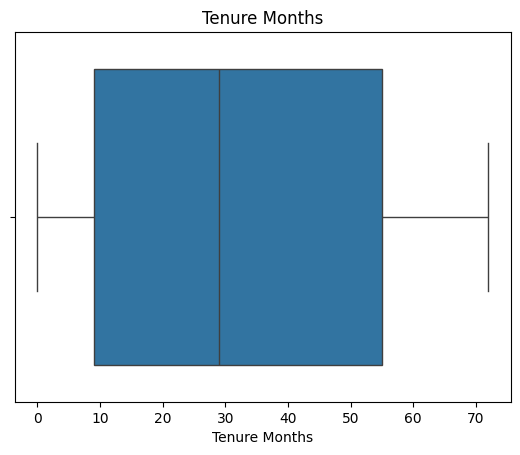

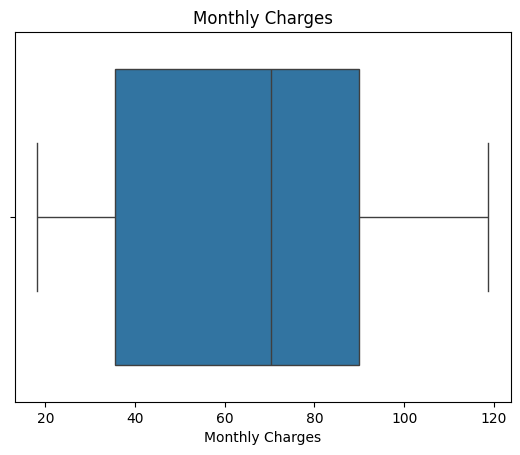

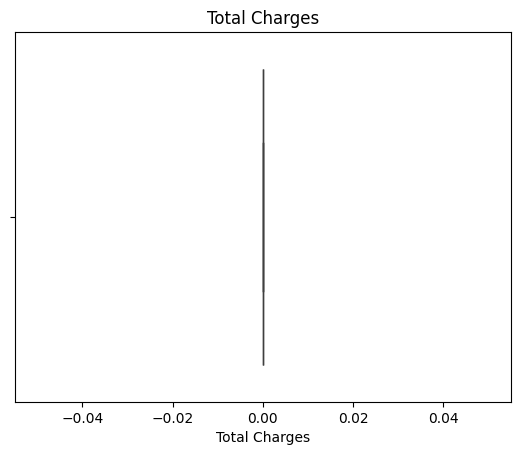

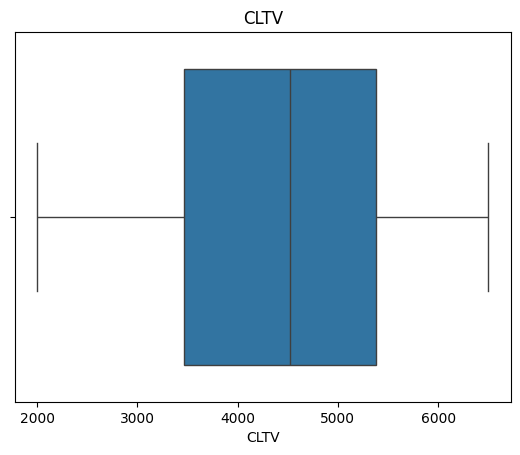

In [ ]:
for col in outlier_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

Final check

In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Customer IDs:")
print(df['CustomerID'].duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Distribution:")
print(df['Churn Value'].value_counts(normalize=True))

Dataset Shape: (7043, 33)

Missing Values:
0

Duplicate Rows:
0

Duplicate Customer IDs:
0

Data Types:
CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Label           object
Churn Value            int64
Churn Score            int

SQL Analysis & Business Questions

In [ ]:
import sqlite3

conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

def run(query, quiet=False):
    cursor.execute(query)
    conn.commit()
    if not quiet:
        return cursor.fetchall()

In [ ]:
import sqlite3
conn = sqlite3.connect('telco_churn.db')
cursor = conn.cursor()
df.to_sql('telco_customers', conn, if_exists='replace', index=False)

7043

1. What is the overall percentage of customers who churned compared to the total number of customers?

In [ ]:
query = """SELECT
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers;"""

pd.read_sql_query(query, conn_file)

,total_customers,churned_customers,churn_rate_percentage
0,7043,1869,26.54


2. How does the churn rate vary across different contract types?

In [ ]:
query = """SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY Contract
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn_file)

,Contract,total_customers,churned_customers,churn_rate_percentage
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


3. What is the average monthly charge for churned customers compared to retained customers?

In [ ]:
query = """SELECT
    "Churn Label",
    ROUND(AVG("Monthly Charges"), 2) AS avg_monthly_charges
FROM telco_customers
GROUP BY "Churn Label";"""

pd.read_sql_query(query, conn_file)

,Churn Label,avg_monthly_charges
0,No,61.27
1,Yes,74.44


4. What are the top 5 most common reasons for customer churn?

In [ ]:
query = """SELECT
    "Churn Reason",
    COUNT(*) AS count
FROM telco_customers
WHERE "Churn Value" = 1
GROUP BY "Churn Reason"
ORDER BY count DESC
LIMIT 5;"""

pd.read_sql_query(query, conn_file)

,Churn Reason,count
0,Attitude of support person,192
1,Competitor offered higher download speeds,189
2,Competitor offered more data,162
3,Don't know,154
4,Competitor made better offer,140


5. Which internet service type has the highest customer churn rate?

In [ ]:
query = """SELECT
    "Internet Service",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Internet Service"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn_file)

,Internet Service,total_customers,churned_customers,churn_rate_percentage
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


6. How does the churn rate differ across various payment methods?

In [ ]:
query = """SELECT
    "Payment Method",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Payment Method"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn_file)

,Payment Method,total_customers,churned_customers,churn_rate_percentage
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


7. What is the churn rate among senior citizens compared to non-senior citizens?

In [ ]:
query = """SELECT
    "Senior Citizen",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Senior Citizen";"""

pd.read_sql_query(query, conn_file)

,Senior Citizen,total_customers,churned_customers,churn_rate_percentage
0,No,5901,1393,23.61
1,Yes,1142,476,41.68


8. What is the average tenure (in months) of customers who churned?

In [ ]:
query = """SELECT
    ROUND(AVG("Tenure Months"), 2) AS avg_tenure_months
FROM telco_customers
WHERE "Churn Value" = 1;"""

pd.read_sql_query(query, conn_file)

,avg_tenure_months
0,17.98


9. Who are the high-paying customers (monthly charges > 80) that churned, and what are their payment methods?

In [ ]:
query = """SELECT
    CustomerID,
    "Monthly Charges",
    "Tenure Months",
    "Payment Method"
FROM telco_customers
WHERE "Churn Value" = 1
  AND "Monthly Charges" > 80
ORDER BY "Monthly Charges" DESC;"""

pd.read_sql_query(query, conn_file)

,CustomerID,Monthly Charges,Tenure Months,Payment Method
0,8199-ZLLSA,118.35,67,Bank transfer (automatic)
1,2889-FPWRM,117.80,72,Bank transfer (automatic)
2,2302-ANTDP,117.45,48,Electronic check
3,9053-JZFKV,116.20,67,Credit card (automatic)
4,1444-VVSGW,115.65,70,Credit card (automatic)
...,...,...,...,...
901,7693-LCKZL,80.15,5,Electronic check
902,6204-IEUXJ,80.10,3,Credit card (automatic)
903,4277-PVRAN,80.10,8,Bank transfer (automatic)
904,4547-KQRTM,80.05,10,Bank transfer (automatic)


10. How does having online security impact the customer churn rate?

In [ ]:
query = """SELECT
    "Online Security",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Online Security"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn_file)

,Online Security,total_customers,churned_customers,churn_rate_percentage
0,No,3498,1461,41.77
1,Yes,2019,295,14.61
2,No internet service,1526,113,7.40
